# Beam scanning: galvos, polygons, MEMS mirrors, phased arrays and Risley prisms

A scanning LiDAR builds its point cloud one direction at a time: the
laser beam (and the receiver's field of view with it) is steered over
the scene, a hundred thousand to a few million directions per second.
The scanner decides the field of view, the angular resolution, the frame
rate, the size of the receiver aperture and a good deal of the cost.
The same scanners write with lasers (marking, printing, lithography
direct write), project images (laser displays, notebook 87,
speckle reduction) and steer beams in free space communication.

This notebook compares the main kinds with the `lidar` module:

1. resolvable spots: what the product of aperture and angle buys,
2. galvanometer mirrors: two mirrors in a row and the bowed scan field,
3. polygon mirrors: fast lines, duty cycle and pupil wander,
4. resonant MEMS mirrors: sinusoidal scans, point density and Lissajous
   patterns,
5. optical phased arrays: steering without moving parts, grating lobes,
   phase quantization and errors, wavelength steering,
6. Risley prisms: two rotating wedges and their rosette patterns.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import lidar
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

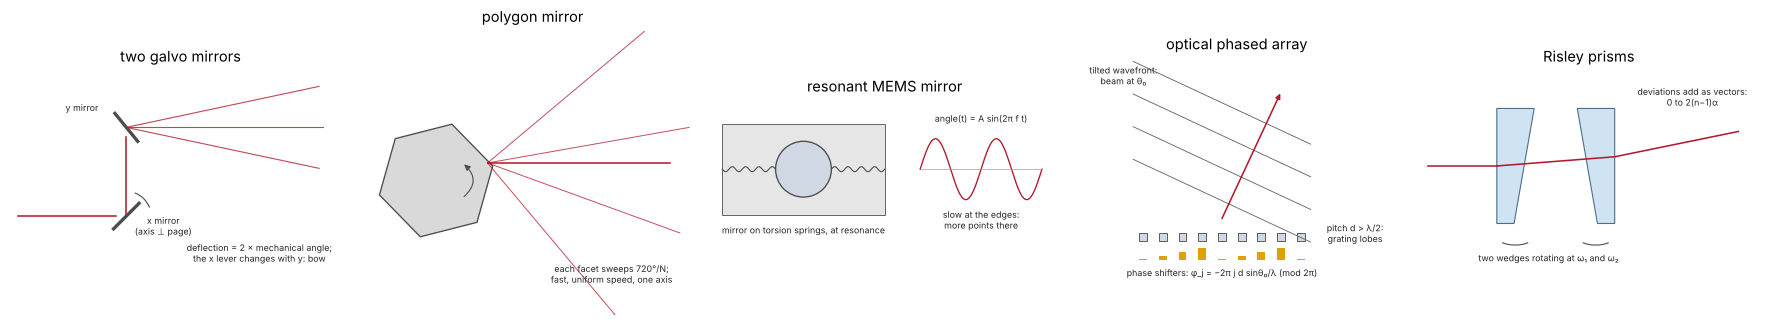

In [2]:
fig, axs = plt.subplots(1, 5, figsize=(22, 4.2), layout="constrained")
names = {"galvo": "two galvo mirrors", "polygon": "polygon mirror", "mems": "resonant MEMS mirror",
         "opa": "optical phased array", "risley": "Risley prisms"}
for ax, kind in zip(axs, names):
    sketch.beam_scanner(ax, kind, title=names[kind])
plt.show()

## 1. Resolvable spots

A beam of diameter $D$ diverges by about $a\lambda/D$ ($a = 1.27$ for a
Gaussian beam of 1/e² diameter $D$). A scanner that sweeps it over the
optical angle $\theta$ can address

$$
N = \frac{\theta D}{a\lambda}
$$

distinct directions, a number that no optics after the scanner can
increase: a telescope that widens the beam by $M$ shrinks the angle by
$M$ (the étendue of the beam is conserved, notebook 83, étendue). The
product $\theta D$ is the figure of merit of a scanner, together with its
speed. A LiDAR with 0.1° resolution (1.7 mrad) over 120° needs about
1200 spots per line; at 1550 nm that is a beam of at least 1.2 mm with
a full optical scan of 120°, or 12 mm with 12° and a 10× telescope.
Typical numbers:

In [3]:
LAM = 1550e-9
scanners = [("galvo (10 mm mirror)", 10e-3, np.radians(40), "kHz steps, any path"),
            ("polygon (20 mm facet, 8 beam)", 8e-3, np.radians(90), "10-100 lines/ms"),
            ("resonant MEMS (2 mm)", 2e-3, np.radians(40), "10-30 kHz, sine"),
            ("quasi-static MEMS (5 mm)", 5e-3, np.radians(20), "~1 kHz, any path"),
            ("OPA (1 mm, 512 el.)", 1e-3, np.radians(50), "µs, random access"),
            ("Risley prisms (25 mm)", 25e-3, np.radians(30), "rosette, Hz-kHz")]
print("{:32s} {:>8s} {:>9s} {:>12s}   {}".format("scanner", "D (mm)", "θ (deg)", "spots N", "speed"))
for name, D, th, speed in scanners:
    print("{:32s} {:8.1f} {:9.0f} {:12.0f}   {}".format(name, D*1e3, np.degrees(th),
                                                       lidar.resolvable_spots(th, D, LAM, 1.27), speed))

scanner                            D (mm)   θ (deg)      spots N   speed
galvo (10 mm mirror)                 10.0        40         3547   kHz steps, any path
polygon (20 mm facet, 8 beam)         8.0        90         6384   10-100 lines/ms
resonant MEMS (2 mm)                  2.0        40          709   10-30 kHz, sine
quasi-static MEMS (5 mm)              5.0        20          887   ~1 kHz, any path
OPA (1 mm, 512 el.)                   1.0        50          443   µs, random access
Risley prisms (25 mm)                25.0        30         6650   rosette, Hz-kHz


The resolvable spot counts are in the hundreds to thousands: enough for
a LiDAR line, though small MEMS mirrors and OPAs need several beams or
a telescope to reach the resolution of a polygon. They differ in speed, in how freely
they can move (a resonant mirror only follows its sine, a galvo goes
anywhere slowly, a phased array jumps anywhere in microseconds), and
in the receiver: a scanner that steers both the outgoing beam and the
received light (coaxial) must have an aperture of the receiver's size,
or the receiver must look at the whole field with a detector array.

## 2. Two galvanometer mirrors

A galvanometer scanner turns a mirror on a motor shaft; two of them, one
behind the other, steer in x and y. Each deflects the beam by twice its
mechanical angle. Because the x mirror sits in front of the y mirror,
the effective lever arm of x changes with the y angle: the scan lines on
a flat field are bowed (often called pincushion distortion of XY scanners).
`galvo_xy()` traces the beam exactly.

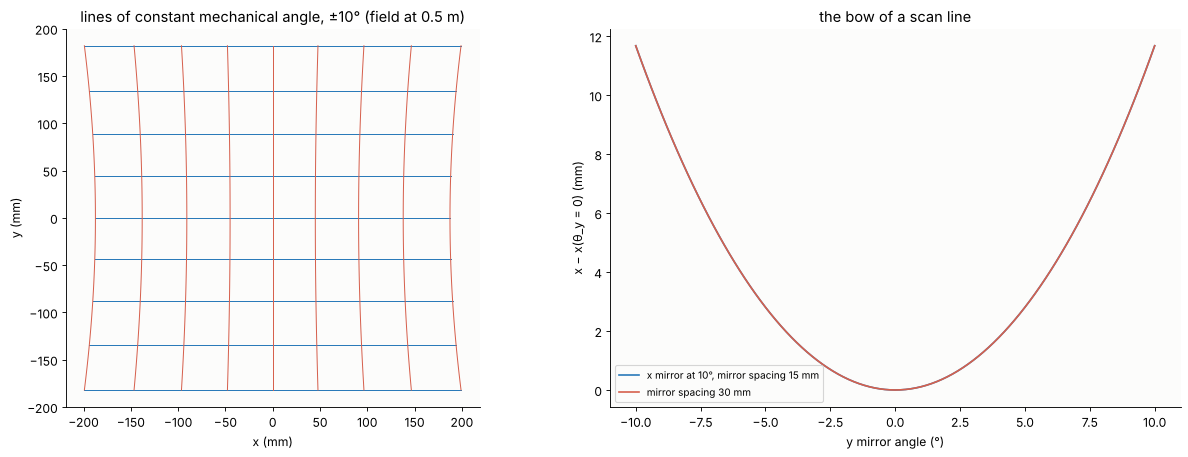

bow at the corner: 11.68 mm of 187 mm half field (6.23%)


In [4]:
SEP, DIST = 0.015, 0.5               # mirror spacing and field distance (m)
ang = np.radians(np.linspace(-10, 10, 9))
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), layout="constrained")
for ty in ang:
    tx = np.radians(np.linspace(-10, 10, 101))
    x, y = lidar.galvo_xy(tx, ty, SEP, DIST)
    axs[0].plot(x*1e3, y*1e3, color=BLUE, lw=0.9)
for tx in ang:
    ty = np.radians(np.linspace(-10, 10, 101))
    x, y = lidar.galvo_xy(tx, ty, SEP, DIST)
    axs[0].plot(x*1e3, y*1e3, color=RED, lw=0.9)
axs[0].set_aspect("equal")
axs[0].set_xlabel("x (mm)")
axs[0].set_ylabel("y (mm)")
axs[0].set_title("lines of constant mechanical angle, ±10° (field at 0.5 m)")

tx = np.radians(10.0)
ty = np.radians(np.linspace(-10, 10, 101))
x, y = lidar.galvo_xy(tx, ty, SEP, DIST)
axs[1].plot(np.degrees(ty), (x - x[50])*1e3, color=BLUE, label="x mirror at 10°, mirror spacing 15 mm")
x2, _ = lidar.galvo_xy(tx, ty, 0.03, DIST)
axs[1].plot(np.degrees(ty), (x2 - x2[50])*1e3, color=RED, label="mirror spacing 30 mm")
axs[1].set_xlabel("y mirror angle (°)")
axs[1].set_ylabel("x − x(θ_y = 0) (mm)")
axs[1].set_title("the bow of a scan line")
axs[1].legend(fontsize=9)
plt.show()
print("bow at the corner: {:.2f} mm of {:.0f} mm half field ({:.2%})".format(
    (x[0] - x[50])*1e3, x[50]*1e3, (x[0] - x[50])/x[50]))

The y lines (blue, constant y mirror angle) are straight in the middle
and the x lines (red) bend outwards at large y angles: the corner of a
±10° scan is 10 mm wider than the centre at 0.5 m, 6 % of the half field.
The bow does not depend much on the mirror spacing (it comes from the
y mirror tilting the plane in which the x deflection lies); it is
corrected by a lookup table in the control, or optically with an
f-theta lens in laser processing. Galvos move freely but slowly: a 10 mm
mirror steps in about 0.2 ms, enough for a few hundred lines per second.

## 3. Polygon mirrors

A spinning polygon with $N$ facets reflects the beam off one facet at a
time; each facet sweeps the beam over $720°/N$ (twice the facet angle)
before the next one takes over and the beam jumps back. Polygons spin at
tens of thousands of rpm and draw lines with constant angular speed,
which makes them the scanners of laser printers and of many automotive
LiDARs. Two practical limits: when the beam straddles a corner, part of
it goes to the wrong direction (the duty cycle is about
$1 - D/\ell$ for a beam of width $D$ on a facet of length $\ell$), and the
point where the beam hits the facet moves during the sweep (pupil
wander), so a lens after the polygon sees a moving beam.

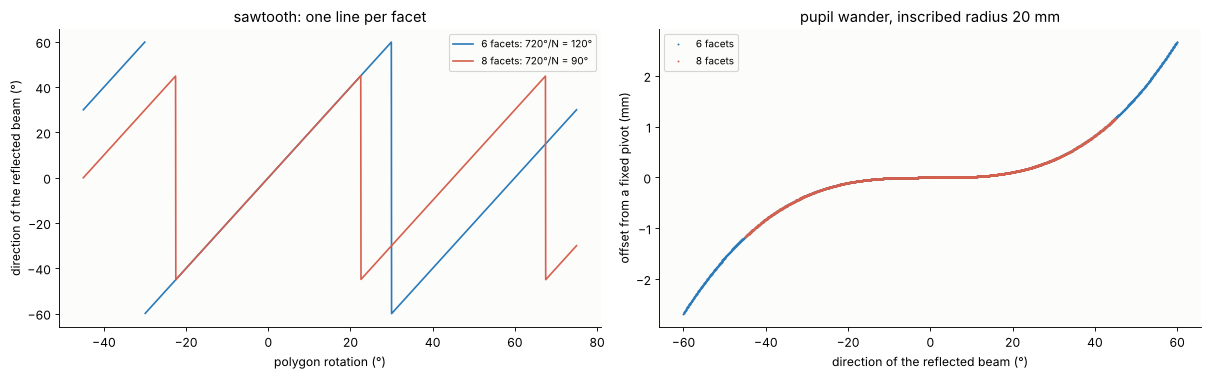

In [5]:
rot = np.radians(np.linspace(-45, 75, 2001))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for n_f, R_in, c in ((6, 0.02, BLUE), (8, 0.02, RED)):
    a, p = lidar.polygon_scan(rot, n_f, R_in)
    axs[0].plot(np.degrees(rot), np.degrees(a), color=c, label="{} facets: 720°/N = {:.0f}°".format(
        n_f, 720/n_f))
    # lateral offset of the reflected ray from a fixed pivot at the facet centre (R_in, 0):
    # zero for a mirror that turns about the point where the beam hits it, like a galvo
    offset = (p[:, 0] - R_in)*np.sin(a) - p[:, 1]*np.cos(a)
    axs[1].plot(np.degrees(a), offset*1e3, ".", ms=1.5, color=c, label="{} facets".format(n_f))
axs[0].set_xlabel("polygon rotation (°)")
axs[0].set_ylabel("direction of the reflected beam (°)")
axs[0].set_title("sawtooth: one line per facet")
axs[0].legend(fontsize=9)
axs[1].set_xlabel("direction of the reflected beam (°)")
axs[1].set_ylabel("offset from a fixed pivot (mm)")
axs[1].set_title("pupil wander, inscribed radius 20 mm")
axs[1].legend(fontsize=9)
plt.show()

In [6]:
for n_f in (6, 8, 12):
    facet = 2*0.02*np.tan(np.pi/n_f)
    for D in (2e-3, 8e-3):
        print("{:2d} facets ({:.1f} mm long), beam {:.0f} mm: duty cycle {:.0%}, line of {:.0f}°".format(
            n_f, facet*1e3, D*1e3, 1 - D/facet, 720/n_f*(1 - D/facet)))

 6 facets (23.1 mm long), beam 2 mm: duty cycle 91%, line of 110°
 6 facets (23.1 mm long), beam 8 mm: duty cycle 65%, line of 78°
 8 facets (16.6 mm long), beam 2 mm: duty cycle 88%, line of 79°
 8 facets (16.6 mm long), beam 8 mm: duty cycle 52%, line of 47°
12 facets (10.7 mm long), beam 2 mm: duty cycle 81%, line of 49°
12 facets (10.7 mm long), beam 8 mm: duty cycle 25%, line of 15°


The beam direction is a sawtooth of the rotation with a slope of 2.
The facet turns about the polygon's axis, not about the point where the
beam hits it, so the reflected beam does not pivot about a fixed point:
against a pivot at the facet centre, its lateral offset changes by
±2.7 mm over the 120° sweep of a 6 facet polygon (20 mm inscribed
radius) and by ±1.1 mm over the 90° of an 8 facet one, and a lens after the polygon sees a beam that
wanders across its aperture. A larger beam (a larger receiver aperture)
needs longer facets, so the polygon grows with the aperture: an 8 mm
beam on a 6 facet polygon of 20 mm inscribed radius loses a third of
every sweep. LiDAR polygons are often used with the beam hitting the
facets at an angle, and with facets tilted by different amounts so that
each facet scans another line: a polygon with 4 facets tilted by
steps of 2° draws four lines per turn.

## 4. Resonant MEMS mirrors

A MEMS mirror of a few millimetres, etched from silicon and hung on
torsion springs, swings at its mechanical resonance, 1 to 30 kHz, with
large amplitude for little power. Its angle is a sine,
$\theta(t) = A\sin(2\pi f t)$: fast in the middle, slow at the turning
points. Equally spaced pulses in time therefore crowd at the edges of
the field: the density of points follows the arcsine law
$p(\theta) = 1/(\pi\sqrt{A^2 - \theta^2})$. LiDARs either use only the
middle part, fire at times spaced for equal angles, or accept the
crowding.

Two axes at different resonance frequencies draw a **Lissajous**
pattern, which covers the field gradually and only repeats after the
least common period of both frequencies.

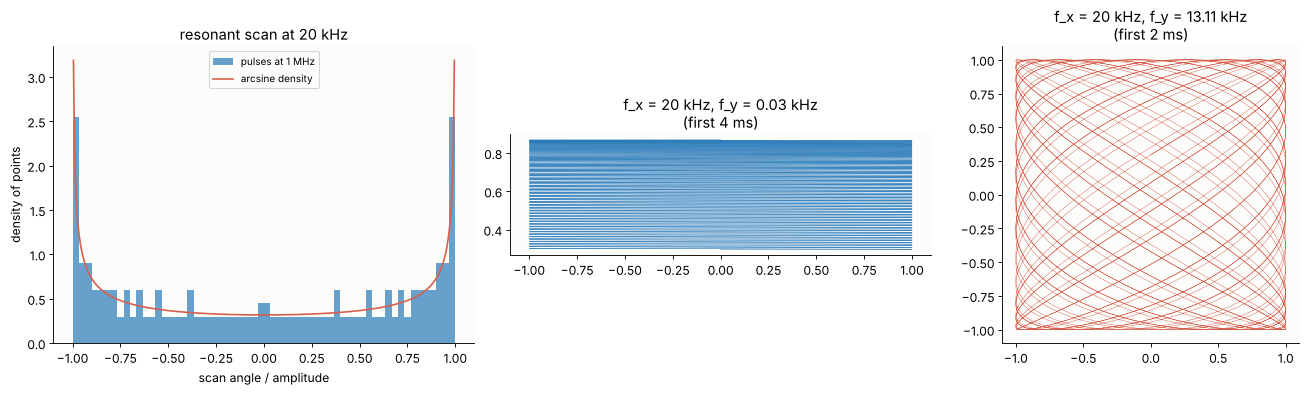

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
A = 1.0
t = np.arange(200000)/200e6*50
th = A*np.sin(2*np.pi*20e3*t)
axs[0].hist(th, bins=60, density=True, color=BLUE, alpha=0.7, label="pulses at 1 MHz")
x = np.linspace(-0.995, 0.995, 400)
axs[0].plot(x, 1/(np.pi*np.sqrt(A**2 - x**2)), color=RED, label="arcsine density")
axs[0].set_xlabel("scan angle / amplitude")
axs[0].set_ylabel("density of points")
axs[0].set_title("resonant scan at 20 kHz")
axs[0].legend(fontsize=9)
for ax, (fx, fy, c, t_show) in zip(axs[1:], ((20e3, 30.0, BLUE, 4e-3), (20e3, 13.11e3, RED, 2e-3))):
    tt = np.arange(0, t_show, 1/2e6)
    x, y = lidar.lissajous(tt, fx, fy, phase=0.3)
    ax.plot(x, y, color=c, lw=0.4)
    ax.set_aspect("equal")
    ax.set_title("f_x = {:g} kHz, f_y = {:g} kHz\n(first {:g} ms)".format(fx/1e3, fy/1e3, t_show*1e3))
plt.show()

The histogram of directions follows the arcsine density: the outer 10 %
of the scan angle on each side take 29 % of the pulses. With a slow
second axis (30 Hz) the pattern is a raster; with two fast axes it
becomes a Lissajous figure, whose density is concentrated at the edges
and corners. How fast does each pattern cover the field? The coverage
is the fraction of cells of a 60 × 60 grid visited after a time $t$,
with a pulse about every microsecond (a pulse rate that is not a
multiple of the mirror frequency, or the pulses would hit the same few
columns forever):

raster, 20 kHz × 30 Hz          : 90 % of the cells after 22.0 ms ; 100% after 100 ms
Lissajous, 20 kHz × 13.11 kHz   : 90 % of the cells after 10.9 ms ; 100% after 100 ms
Lissajous, 20 kHz × 19.37 kHz   : 90 % of the cells after 15.5 ms ; 100% after 100 ms
Lissajous, 20 kHz × 19.9 kHz    : never 90 % ; 82% after 100 ms


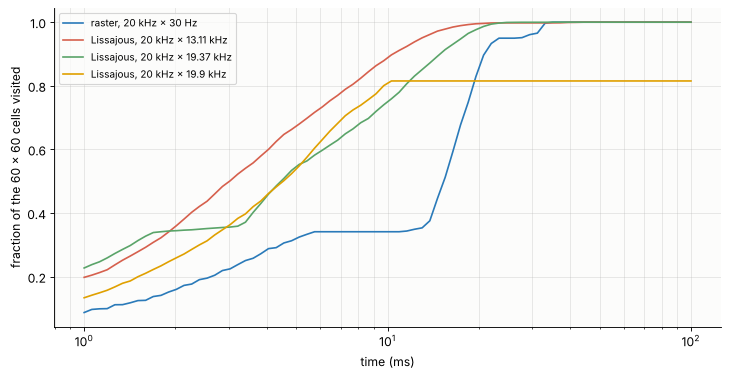

In [8]:
def coverage(fx, fy, t_max, n_grid=60, prf=997.3e3):
    tt = np.arange(0, t_max, 1/prf)
    x, y = lidar.lissajous(tt, fx, fy, phase=0.3)
    i = np.clip(((x + 1)/2*n_grid).astype(int), 0, n_grid - 1)
    j = np.clip(((y + 1)/2*n_grid).astype(int), 0, n_grid - 1)
    first = np.full(n_grid*n_grid, np.inf)
    idx = i*n_grid + j
    np.minimum.at(first, idx, tt)
    times = np.logspace(-3, np.log10(t_max), 80)
    return times, np.array([np.mean(first <= tm) for tm in times])


fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
for (fx, fy), c, name in (((20e3, 30.0), BLUE, "raster, 20 kHz × 30 Hz"),
                          ((20e3, 13.11e3), RED, "Lissajous, 20 kHz × 13.11 kHz"),
                          ((20e3, 19.37e3), GREEN, "Lissajous, 20 kHz × 19.37 kHz"),
                          ((20e3, 19.9e3), ORANGE, "Lissajous, 20 kHz × 19.9 kHz")):
    tm, cov = coverage(fx, fy, 0.1)
    ax.semilogx(tm*1e3, cov, color=c, label=name)
    print("{:32s}: {} ; {:.0%} after 100 ms".format(
        name, "90 % of the cells after {:.1f} ms".format(tm[np.argmax(cov >= 0.9)]*1e3)
        if np.any(cov >= 0.9) else "never 90 %", cov[-1]))
ax.set_xlabel("time (ms)")
ax.set_ylabel("fraction of the 60 × 60 cells visited")
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which="both")
plt.show()

The raster covers the field line by line, in a little more than one half
period of its slow axis (90 % after 22 ms; the sine is slow at its
ends). The Lissajous
pattern of 20 × 13.11 kHz covers 90 % of the cells in about 10 ms,
everywhere coarsely first and then finer, which suits a LiDAR that
wants a complete low resolution frame early. The frequency ratio
matters: 20 × 19.9 kHz repeats itself every 10 ms (the beat of
100 Hz), and the cells between its lines are never visited: it stalls
at 82 %. MEMS
LiDARs choose the ratio, and lock the two resonances to it, so that
the pattern repeats once per frame with the desired density.

## 5. Optical phased arrays

An optical phased array (OPA) steers without moving parts: a row of $N$
waveguide emitters with the pitch $d$, each with its own phase shifter,
radiates a far field that is the Fourier transform of the emitter
phases. A linear phase ramp $\varphi_j = -2\pi j d\sin\theta_0/\lambda$
tilts the wavefront and steers the beam to $\theta_0$; the array factor
is

$$
|AF(\theta)|^2 = \left|\frac{1}{N}\sum_j e^{i(2\pi j d\sin\theta/\lambda + \varphi_j)}\right|^2 ,
$$

with a main lobe of width about $\lambda/(Nd)$ and **grating lobes** at
$\sin\theta = \sin\theta_0 + m\lambda/d$. Only a pitch below $\lambda/2$
keeps the grating lobes out of the visible range for all steering
angles; silicon waveguides at 1550 nm need about 2 µm of spacing to
avoid crosstalk, so practical OPAs have grating lobes, or use
non-uniform spacing.

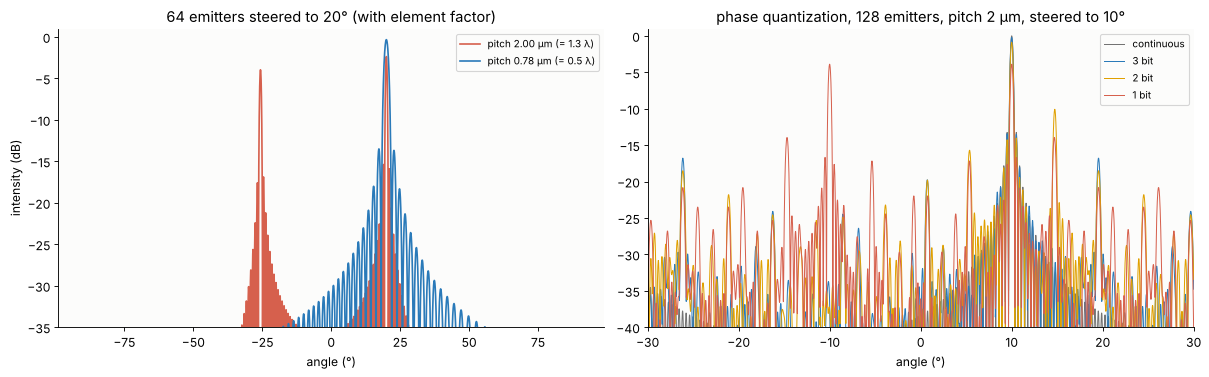

In [9]:
s = np.linspace(-1, 1, 6001)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for d, c in ((2.0e-6, RED), (0.775e-6, BLUE)):
    I = lidar.opa_array_factor(s, 64, d, LAM, steer=np.sin(np.radians(20)),
                               element_width=0.9*d)
    axs[0].plot(np.degrees(np.arcsin(s)), 10*np.log10(I + 1e-6), color=c,
                label="pitch {:.2f} µm (= {:.1f} λ)".format(d*1e6, d/LAM))
axs[0].set_ylim(-35, 1)
axs[0].set_xlabel("angle (°)")
axs[0].set_ylabel("intensity (dB)")
axs[0].set_title("64 emitters steered to 20° (with element factor)")
axs[0].legend(fontsize=9)

for bits, c in ((None, GREY), (3, BLUE), (2, ORANGE), (1, RED)):
    I = lidar.opa_array_factor(s, 128, 2e-6, LAM, steer=np.sin(np.radians(10)), phase_bits=bits)
    axs[1].plot(np.degrees(np.arcsin(s)), 10*np.log10(I + 1e-6), color=c, lw=0.9,
                label="continuous" if bits is None else "{} bit".format(bits))
axs[1].set_xlim(-30, 30)
axs[1].set_ylim(-40, 1)
axs[1].set_xlabel("angle (°)")
axs[1].set_title("phase quantization, 128 emitters, pitch 2 µm, steered to 10°")
axs[1].legend(fontsize=9)
plt.show()

With a pitch of 2 µm (1.3 λ) the beam steered to 20° has a grating lobe
at −26°, nearly as strong as the main lobe: half the power goes the
wrong way, and the receiver sees echoes from two directions. At half
the wavelength the grating lobes vanish. Coarse phase shifters add
spurious lobes: a phase quantized to 2 bits (four levels) leaves the
quantization error periodic along the ramp, which diffracts power into
"quantization lobes"; one bit gives a mirror image of the beam.

Random phase errors (fabrication, temperature) lower the main lobe by
the factor $e^{-\sigma^2}$ (Ruze's formula) and scatter the rest into a
diffuse background. OPAs calibrate every phase shifter for every
direction.

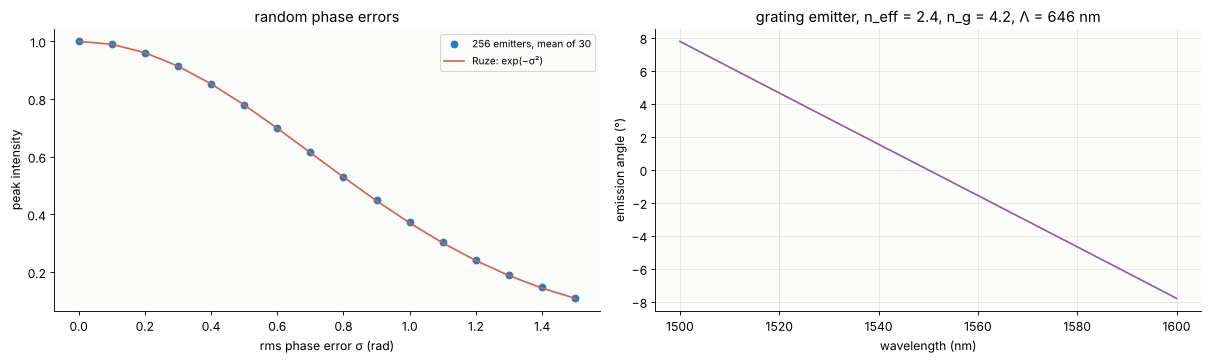

wavelength steering: -0.157 °/nm, 15.6° over 100 nm


In [10]:
sig = np.linspace(0, 1.5, 16)
peaks = [np.mean([lidar.opa_array_factor(0.0, 256, 2e-6, LAM, phase_error=sg, rng=k)
                  for k in range(30)]) for sg in sig]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
axs[0].plot(sig, peaks, "o", color=BLUE, label="256 emitters, mean of 30")
axs[0].plot(sig, np.exp(-sig**2) + (1 - np.exp(-sig**2))/256, color=RED, label="Ruze: exp(−σ²)")
axs[0].set_xlabel("rms phase error σ (rad)")
axs[0].set_ylabel("peak intensity")
axs[0].legend(fontsize=9)
axs[0].set_title("random phase errors")

# wavelength steering of a grating emitter (the other axis)
lam = np.linspace(1500e-9, 1600e-9, 101)
n0, ng = 2.4, 4.2
n_eff = lambda l: n0 + (n0 - ng)*(l - 1550e-9)/1550e-9
period = 1550e-9/n0
th = lidar.grating_emission_angle(lam, n_eff, period)
axs[1].plot(lam*1e9, np.degrees(th), color=PURPLE)
axs[1].set_xlabel("wavelength (nm)")
axs[1].set_ylabel("emission angle (°)")
axs[1].set_title("grating emitter, n_eff = 2.4, n_g = 4.2, Λ = {:.0f} nm".format(period*1e9))
axs[1].grid(alpha=0.3)
plt.show()
print("wavelength steering: {:.3f} °/nm, {:.1f}° over 100 nm".format(
    np.degrees(th[1] - th[0])/1.0, np.degrees(th[0] - th[-1])))

Each emitter is a waveguide grating that radiates upwards along its
length. Its emission angle obeys the grating equation
$\sin\theta = n_\mathrm{eff} - \lambda/\Lambda$, and since the effective
index of a silicon waveguide falls with the wavelength (group index 4.2),
tuning a laser over 100 nm sweeps the beam by about 16° along the
waveguides. A 2D OPA LiDAR thus steers one axis by phase, the other by
wavelength.

## 6. Risley prisms

Two thin wedge prisms in a row each deviate a beam by about
$(n-1)\alpha$ towards their thick ends. Rotated independently, their
deviations add as vectors: aligned they deviate by $2(n-1)\alpha$,
opposed they cancel. Rotating both continuously at $\omega_1$ and
$\omega_2$ draws rosette patterns that fill a cone, with a compact,
robust mechanism: Risley scanners are used in some automotive and
drone LiDARs and in laser communication terminals. `risley_direction()`
refracts the beam exactly at the four surfaces.

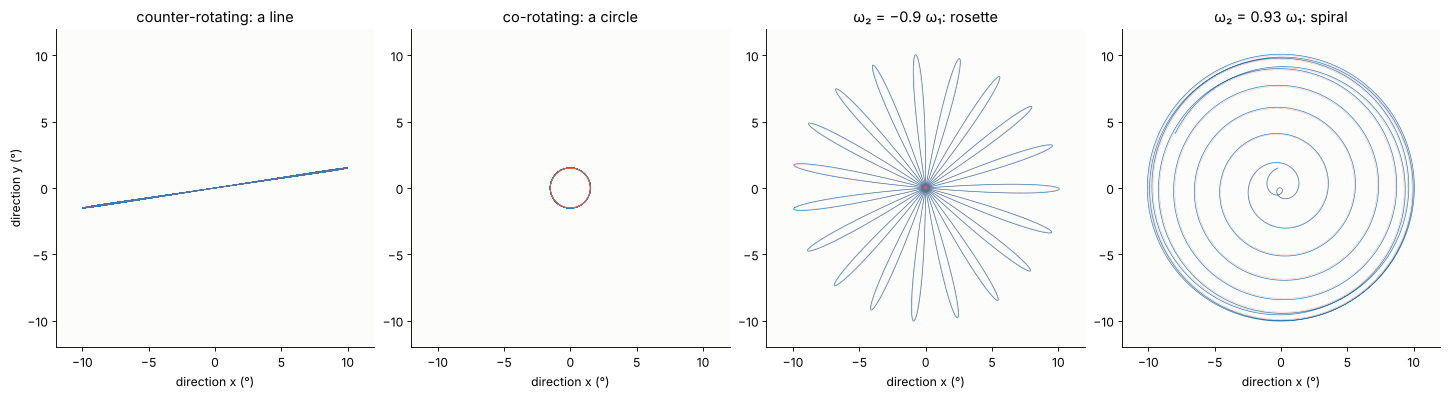

aligned wedges: exact deviation 10.13°, first order 2(n-1)α = 10.00°


In [11]:
WEDGE, N_PR = np.radians(10.0), 1.5
fig, axs = plt.subplots(1, 4, figsize=(18, 4.6), layout="constrained")
tt = np.linspace(0, 1, 3000)
for ax, (r, name) in zip(axs, ((-1.0, "counter-rotating: a line"), (1.0, "co-rotating: a circle"),
                                (-0.9, "ω₂ = −0.9 ω₁: rosette"), (0.93, "ω₂ = 0.93 ω₁: spiral"))):
    n_turns = 10
    phi1 = 2*np.pi*n_turns*tt
    phi2 = r*phi1 + (np.pi if r > 0 else 0.0) + 0.3
    d = lidar.risley_direction(phi1, phi2, WEDGE, N_PR)
    ax.plot(np.degrees(d[:, 0]), np.degrees(d[:, 1]), color=BLUE, lw=0.6)
    # first order: vector sum
    dev = (N_PR - 1)*WEDGE
    fx = -dev*(np.cos(phi1) + np.cos(phi2))
    fy = -dev*(np.sin(phi1) + np.sin(phi2))
    ax.plot(np.degrees(fx), np.degrees(fy), color=RED, lw=0.4, ls=":")
    ax.set_aspect("equal")
    ax.set_xlim(-12, 12)
    ax.set_ylim(-12, 12)
    ax.set_title(name)
    ax.set_xlabel("direction x (°)")
axs[0].set_ylabel("direction y (°)")
plt.show()
d = lidar.risley_direction(0.0, 0.0, WEDGE, N_PR)
print("aligned wedges: exact deviation {:.2f}°, first order 2(n-1)α = {:.2f}°".format(
    np.degrees(np.arcsin(np.hypot(d[0], d[1]))), np.degrees(2*(N_PR - 1)*WEDGE)))

Counter-rotating wedges at equal speed scan a straight line, co-rotating
ones a circle; nearly equal speeds draw rosettes and spirals that fill
the disk of radius $2(n-1)\alpha$ (here 10°). The exact directions (blue)
differ from the first order vector sum (red dotted) by a few per cent
at the edge: real Risley scanners use the exact ray trace, or a
calibration, to convert prism angles into directions, and have to solve
the inverse problem (which prism angles point to a given direction) for
pointing. The pattern is densest at the edge and the centre; uniform
coverage needs non-constant speeds.

## Summary

- The number of resolvable spots $\theta D/(a\lambda)$ is the invariant of
  a scanner; telescopes trade angle for aperture.
- Two galvo mirrors steer freely but slowly, with a bowed scan field
  that a lookup table corrects. Polygons draw fast lines with constant
  speed, at the price of a duty cycle and pupil wander that grow with
  the beam.
- Resonant MEMS mirrors are small, fast and cheap; their sinusoidal
  motion crowds points at the edges, and two resonant axes draw
  Lissajous patterns that cover the field coarse to fine.
- Optical phased arrays steer by phase alone in microseconds, but have
  grating lobes unless the pitch is below λ/2, lobes from quantized
  phases, and lose peak power as $e^{-\sigma^2}$ with phase errors; the
  second axis is steered by wavelength.
- Risley prisms fill a cone with rosettes from two rotating wedges.

## References

- G. F. Marshall and G. E. Stutz (eds.), *Handbook of Optical and Laser
  Scanning*, 2nd ed., CRC Press (2011).
- P. F. McManamon et al., "Optical phased array technology", Proc. IEEE
  84, 268 (1996).
- C. V. Poulton et al., "Long-range LiDAR and free-space data
  communication with high-performance optical phased arrays", IEEE J.
  Sel. Top. Quantum Electron. 25, 7700108 (2019).
- D. Wang, C. Watkins and H. Xie, "MEMS mirrors for LiDAR: a review",
  Micromachines 11, 456 (2020).
- Y. Li, "Third-order theory of the Risley-prism-based beam steering
  system", Appl. Opt. 50, 679 (2011).
- J. Ruze, "Antenna tolerance theory – a review", Proc. IEEE 54, 633
  (1966).

In [12]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 3 s
